In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/varunika18/cyber-complaints/complaints.csv


In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/varunika18/cyber-complaints/complaints.csv")

print(df.shape)
print(df.columns)
df.head()

(18338, 4)
Index(['category', 'sub_category', 'crimeaditionalinfo', 'is_short'], dtype='object')


,category,sub_category,crimeaditionalinfo,is_short
0,Online and Social Media Related Crime,Provocative Speech for unlawful acts,i was sent a msg on whatsapp and she said she ...,False
1,Cyber Attack/ Dependent Crimes,Hacking/Defacement,i never imagined something like this could hap...,False
2,Online and Social Media Related Crime,Online Job Fraud,online job add was posted in facebook in group...,False
3,Online Financial Fraud,DebitCredit Card FraudSim Swap Fraud,citizen details namenaresh pshalirwaas distchu...,False
4,Online and Social Media Related Crime,FakeImpersonating Profile,one fake id has been created in my facebook ac...,False


In [3]:
# Check missing values

print(df[["crimeaditionalinfo", "category"]].isnull().sum())

crimeaditionalinfo    0
category              0
dtype: int64


In [4]:
# Check duplicate complaint texts

duplicate_count = df["crimeaditionalinfo"].duplicated().sum()

print("Total complaints:", len(df))
print("Duplicate complaints:", duplicate_count)
print("Duplicate percentage:", round((duplicate_count / len(df)) * 100, 2), "%")

Total complaints: 18338
Duplicate complaints: 0
Duplicate percentage: 0.0 %


In [5]:
# Check crime category distribution

category_counts = df["category"].value_counts()

print(category_counts)
print("\nNumber of categories:", df["category"].nunique())

category
Online and Social Media Related Crime                   4746
Online Financial Fraud                                  4255
Cyber Attack/ Dependent Crimes                          3608
Hacking  Damage to computercomputer system etc          1587
Sexually Obscene material                               1543
Any Other Cyber Crime                                   1543
Cryptocurrency Crime                                     465
Child Pornography CPChild Sexual Abuse Material CSAM     350
RapeGang Rape RGRSexually Abusive Content                241
Name: count, dtype: int64

Number of categories: 9


In [6]:
df["category"] = df["category"].replace({
    "Hacking  Damage to computercomputer system etc":
        "Hacking / Computer System Damage",

    "Online and Social Media Related Crime":
        "Online & Social Media Crime",

    "RapeGang Rape RGRSexually Abusive Content":
        "Rape / Sexually Abusive Content",

    "Child Pornography CPChild Sexual Abuse Material CSAM":
        "Child Sexual Abuse Material"
})

In [7]:
print(df["category"].value_counts())

category
Online & Social Media Crime         4746
Online Financial Fraud              4255
Cyber Attack/ Dependent Crimes      3608
Hacking / Computer System Damage    1587
Sexually Obscene material           1543
Any Other Cyber Crime               1543
Cryptocurrency Crime                 465
Child Sexual Abuse Material          350
Rape / Sexually Abusive Content      241
Name: count, dtype: int64


In [8]:
# Select input and target columns

X = df["crimeaditionalinfo"]
y = df["category"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (18338,)
Target shape: (18338,)


In [9]:
from sklearn.model_selection import train_test_split

# First, separate the final test set
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Then split the remaining data into training and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.25,
    random_state=42,
    stratify=y_trainval
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 11002
Validation samples: 3668
Testing samples: 3668


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50000,
    min_df=2
)

# Fit ONLY on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test data only
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (11002, 42262)
Validation TF-IDF shape: (3668, 42262)
Testing TF-IDF shape: (3668, 42262)


In [11]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)
import pandas as pd
import time

model = SGDClassifier(
    loss="log_loss",
    random_state=42,
    learning_rate="optimal"
)

history = []
classes = y_train.unique()

for epoch in range(1, 51):

    start_time = time.time()

    # Train for one epoch
    model.partial_fit(
        X_train_tfidf,
        y_train,
        classes=classes
    )

    # Predictions
    y_train_pred = model.predict(X_train_tfidf)
    y_val_pred = model.predict(X_val_tfidf)

    # Probabilities
    y_train_proba = model.predict_proba(X_train_tfidf)
    y_val_proba = model.predict_proba(X_val_tfidf)

    # Training metrics
    train_accuracy = accuracy_score(y_train, y_train_pred)

    train_precision = precision_score(
        y_train,
        y_train_pred,
        average="weighted",
        zero_division=0
    )

    train_recall = recall_score(
        y_train,
        y_train_pred,
        average="weighted",
        zero_division=0
    )

    train_f1 = f1_score(
        y_train,
        y_train_pred,
        average="weighted",
        zero_division=0
    )

    train_loss = log_loss(
        y_train,
        y_train_proba,
        labels=model.classes_
    )

    # Validation metrics
    val_accuracy = accuracy_score(y_val, y_val_pred)

    val_precision = precision_score(
        y_val,
        y_val_pred,
        average="weighted",
        zero_division=0
    )

    val_recall = recall_score(
        y_val,
        y_val_pred,
        average="weighted",
        zero_division=0
    )

    val_f1 = f1_score(
        y_val,
        y_val_pred,
        average="weighted",
        zero_division=0
    )

    val_loss = log_loss(
        y_val,
        y_val_proba,
        labels=model.classes_
    )

    elapsed_time = time.time() - start_time

    history.append({
        "Epoch": epoch,

        "Train Accuracy": train_accuracy,
        "Train Precision": train_precision,
        "Train Recall": train_recall,
        "Train F1": train_f1,
        "Train Loss": train_loss,

        "Val Accuracy": val_accuracy,
        "Val Precision": val_precision,
        "Val Recall": val_recall,
        "Val F1": val_f1,
        "Val Loss": val_loss,

        "Time (sec)": elapsed_time
    })

    print(
        f"Epoch {epoch:02d}/50 | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed_time:.2f}s"
    )

history_df = pd.DataFrame(history)

Epoch 01/50 | Train Acc: 0.8017 | Val Acc: 0.6794 | Val F1: 0.6442 | Val Loss: 0.9439 | Time: 0.38s
Epoch 02/50 | Train Acc: 0.7939 | Val Acc: 0.6739 | Val F1: 0.6345 | Val Loss: 0.9417 | Time: 0.36s
Epoch 03/50 | Train Acc: 0.7889 | Val Acc: 0.6696 | Val F1: 0.6289 | Val Loss: 0.9413 | Time: 0.38s
Epoch 04/50 | Train Acc: 0.7865 | Val Acc: 0.6682 | Val F1: 0.6265 | Val Loss: 0.9410 | Time: 0.38s
Epoch 05/50 | Train Acc: 0.7841 | Val Acc: 0.6677 | Val F1: 0.6254 | Val Loss: 0.9409 | Time: 0.38s
Epoch 06/50 | Train Acc: 0.7820 | Val Acc: 0.6674 | Val F1: 0.6250 | Val Loss: 0.9408 | Time: 0.38s
Epoch 07/50 | Train Acc: 0.7806 | Val Acc: 0.6677 | Val F1: 0.6250 | Val Loss: 0.9407 | Time: 0.37s
Epoch 08/50 | Train Acc: 0.7800 | Val Acc: 0.6674 | Val F1: 0.6248 | Val Loss: 0.9406 | Time: 0.36s
Epoch 09/50 | Train Acc: 0.7797 | Val Acc: 0.6671 | Val F1: 0.6245 | Val Loss: 0.9405 | Time: 0.36s
Epoch 10/50 | Train Acc: 0.7791 | Val Acc: 0.6668 | Val F1: 0.6243 | Val Loss: 0.9405 | Time: 0.38s


In [12]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

# Final prediction on test set
y_pred = model.predict(X_test_tfidf)
y_pred_proba = model.predict_proba(X_test_tfidf)

# Final test metrics
test_accuracy = accuracy_score(y_test, y_pred)

test_precision = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

test_loss = log_loss(
    y_test,
    y_pred_proba,
    labels=model.classes_
)

print("Final Test Metrics After 50 Epochs")
print("-----------------------------------")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1 Score  : {test_f1:.4f}")
print(f"Log Loss  : {test_loss:.4f}")

Final Test Metrics After 50 Epochs
-----------------------------------
Accuracy  : 0.6832
Precision : 0.6787
Recall    : 0.6832
F1 Score  : 0.6433
Log Loss  : 0.9159


In [13]:
from sklearn.metrics import classification_report

print("Classification Report - Model 1")
print("--------------------------------")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report - Model 1
--------------------------------
                                  precision    recall  f1-score   support

           Any Other Cyber Crime       0.51      0.07      0.12       309
     Child Sexual Abuse Material       0.82      0.13      0.22        70
            Cryptocurrency Crime       0.92      0.58      0.71        93
  Cyber Attack/ Dependent Crimes       1.00      1.00      1.00       722
Hacking / Computer System Damage       0.65      0.59      0.62       317
     Online & Social Media Crime       0.52      0.82      0.64       949
          Online Financial Fraud       0.72      0.81      0.76       851
 Rape / Sexually Abusive Content       0.00      0.00      0.00        48
       Sexually Obscene material       0.50      0.14      0.22       309

                        accuracy                           0.68      3668
                       macro avg       0.63      0.46      0.48      3668
                    weighted avg       0.68  

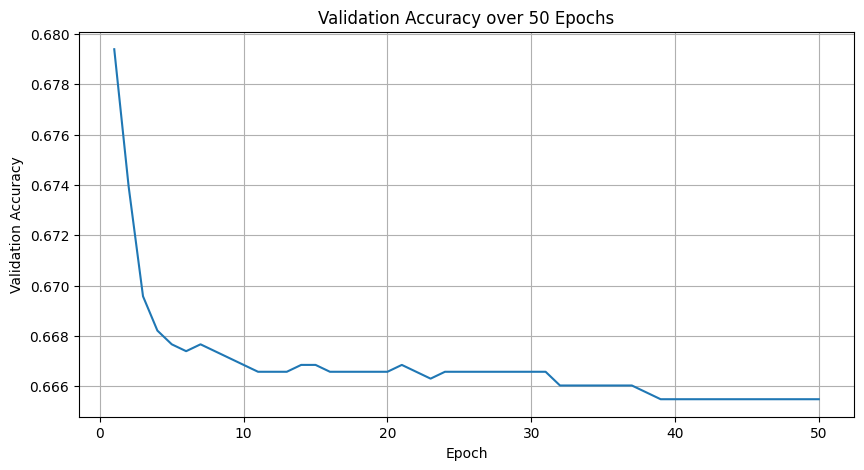

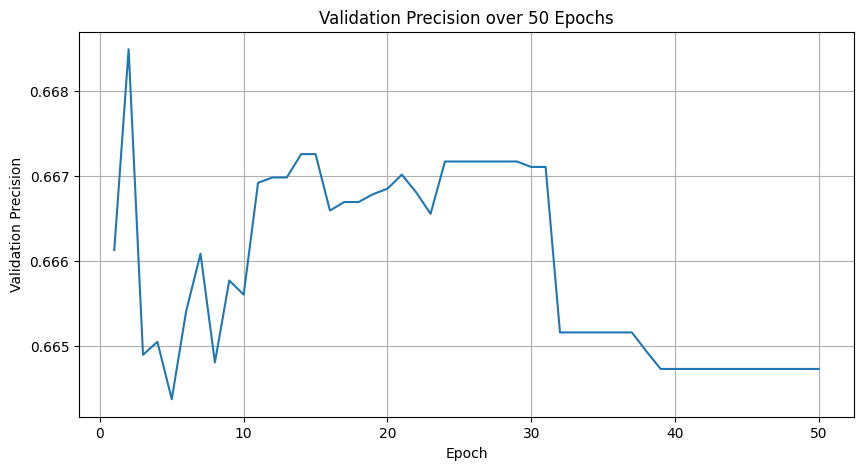

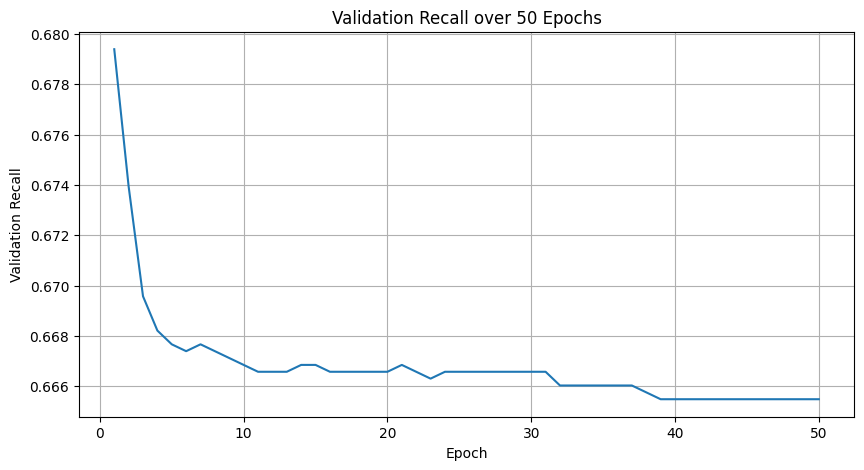

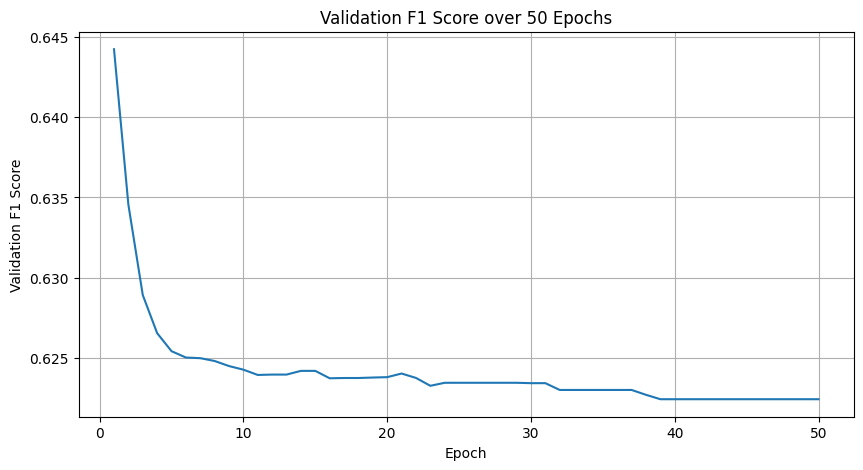

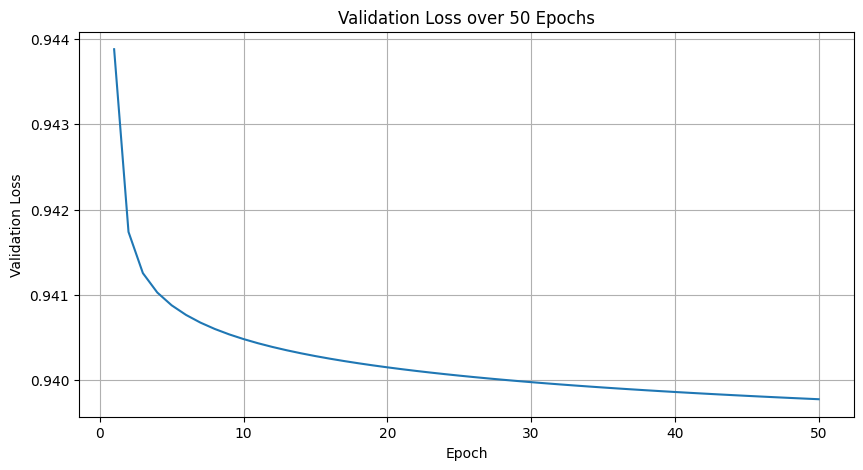

In [14]:
import matplotlib.pyplot as plt

metrics = [
    ("Val Accuracy", "Validation Accuracy"),
    ("Val Precision", "Validation Precision"),
    ("Val Recall", "Validation Recall"),
    ("Val F1", "Validation F1 Score"),
    ("Val Loss", "Validation Loss")
]

for column, title in metrics:
    plt.figure(figsize=(10, 5))
    plt.plot(history_df["Epoch"], history_df[column])
    plt.xlabel("Epoch")
    plt.ylabel(title)
    plt.title(f"{title} over 50 Epochs")
    plt.grid(True)
    plt.show()

In [15]:
model1_results = pd.DataFrame({
    "Model": ["SGD Classifier - Log Loss"],
    "Accuracy": [test_accuracy],
    "Precision": [test_precision],
    "Recall": [test_recall],
    "F1 Score": [test_f1],
    "Log Loss": [test_loss]
})

model1_results

,Model,Accuracy,Precision,Recall,F1 Score,Log Loss
0,SGD Classifier - Log Loss,0.683206,0.67867,0.683206,0.643285,0.915907


In [16]:
new_complaints = [
    "Someone hacked my Instagram account and changed my password.",
    "I received a message asking for my bank account and OTP.",
    "A person sent me an obscene video through social media.",
    "My computer was infected with malware and my files were encrypted.",
    "Someone threatened me through WhatsApp messages."
]

new_tfidf = tfidf.transform(new_complaints)
predictions = model.predict(new_tfidf)

for complaint, prediction in zip(new_complaints, predictions):
    print("Complaint:", complaint)
    print("Predicted Crime Type:", prediction)
    print("-" * 80)

Complaint: Someone hacked my Instagram account and changed my password.
Predicted Crime Type: Hacking / Computer System Damage
--------------------------------------------------------------------------------
Complaint: I received a message asking for my bank account and OTP.
Predicted Crime Type: Online Financial Fraud
--------------------------------------------------------------------------------
Complaint: A person sent me an obscene video through social media.
Predicted Crime Type: Online & Social Media Crime
--------------------------------------------------------------------------------
Complaint: My computer was infected with malware and my files were encrypted.
Predicted Crime Type: Hacking / Computer System Damage
--------------------------------------------------------------------------------
Complaint: Someone threatened me through WhatsApp messages.
Predicted Crime Type: Online & Social Media Crime
----------------------------------------------------------------------------